In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('customer_churn.csv')

In [4]:
df.head()

,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [5]:
df.shape

(500, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        500 non-null    object
 1   Tenure            500 non-null    int64 
 2   MonthlyCharges    500 non-null    int64 
 3   TotalCharges      500 non-null    int64 
 4   Contract          500 non-null    object
 5   PaymentMethod     500 non-null    object
 6   PaperlessBilling  500 non-null    object
 7   SeniorCitizen     500 non-null    int64 
 8   Churn             500 non-null    int64 
dtypes: int64(5), object(4)
memory usage: 35.3+ KB


In [7]:
df.isnull().sum()

,0
CustomerID,0
Tenure,0
MonthlyCharges,0
TotalCharges,0
Contract,0
PaymentMethod,0
PaperlessBilling,0
SeniorCitizen,0
Churn,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,36.532000,113.636000,4237.882000,0.498000,0.106000
std,20.667057,51.799903,2260.619837,0.500497,0.308146
min,1.000000,20.000000,159.000000,0.000000,0.000000
25%,19.000000,67.000000,2237.250000,0.000000,0.000000
50%,37.000000,115.000000,4182.500000,0.000000,0.000000
75%,54.000000,158.000000,6266.750000,1.000000,0.000000
max,71.000000,199.000000,7992.000000,1.000000,1.000000


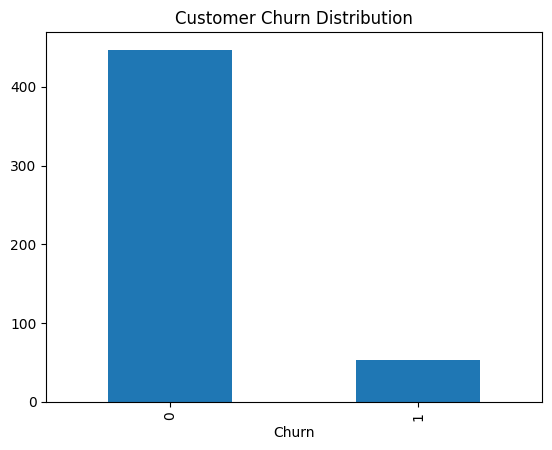

In [10]:
df['Churn'].value_counts().plot(kind='bar')
plt.title('Customer Churn Distribution')
plt.show()

In [11]:
df.select_dtypes(include='object').columns

Index(['CustomerID', 'Contract', 'PaymentMethod', 'PaperlessBilling'], dtype='object')

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Churn'] = le.fit_transform(df['Churn'])

In [13]:
df = pd.get_dummies(df, drop_first=True)

In [14]:
df.head()

,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn,CustomerID_C00002,CustomerID_C00003,CustomerID_C00004,CustomerID_C00005,CustomerID_C00006,...,CustomerID_C00496,CustomerID_C00497,CustomerID_C00498,CustomerID_C00499,CustomerID_C00500,Contract_One year,Contract_Two year,PaymentMethod_Credit Card,PaymentMethod_Electronic Check,PaperlessBilling_Yes
0,6,64,1540,1,0,False,False,False,False,False,...,False,False,False,False,False,True,False,True,False,False
1,21,113,1753,1,0,True,False,False,False,False,...,False,False,False,False,False,False,False,False,True,True
2,27,31,1455,1,0,False,True,False,False,False,...,False,False,False,False,False,False,True,True,False,False
3,53,29,7150,1,0,False,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
4,16,185,1023,1,0,False,False,False,True,False,...,False,False,False,False,False,True,False,False,True,False


In [15]:
df.isnull().sum()

,0
Tenure,0
MonthlyCharges,0
TotalCharges,0
SeniorCitizen,0
Churn,0
...,...
Contract_One year,0
Contract_Two year,0
PaymentMethod_Credit Card,0
PaymentMethod_Electronic Check,0


In [16]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [17]:
num_cols = df.select_dtypes(include=np.number).columns

In [18]:
minmax = MinMaxScaler()

df_minmax = df.copy()
df_minmax[num_cols] = minmax.fit_transform(df[num_cols])

In [19]:
standard = StandardScaler()

df_standard = df.copy()
df_standard[num_cols] = standard.fit_transform(df[num_cols])

In [20]:
print("Original Data:")
print(df[num_cols].head())

print("\nMin-Max Scaling:")
print(df_minmax[num_cols].head())

print("\nStandard Scaling:")
print(df_standard[num_cols].head())

Original Data:
   Tenure  MonthlyCharges  TotalCharges  SeniorCitizen  Churn
0       6              64          1540              1      0
1      21             113          1753              1      0
2      27              31          1455              1      0
3      53              29          7150              1      0
4      16             185          1023              1      0

Min-Max Scaling:
     Tenure  MonthlyCharges  TotalCharges  SeniorCitizen  Churn
0  0.071429        0.245810      0.176305            1.0    0.0
1  0.285714        0.519553      0.203498            1.0    0.0
2  0.371429        0.061453      0.165454            1.0    0.0
3  0.742857        0.050279      0.892506            1.0    0.0
4  0.214286        0.921788      0.110303            1.0    0.0

Standard Scaling:
     Tenure  MonthlyCharges  TotalCharges  SeniorCitizen     Churn
0 -1.478807       -0.959185     -1.194621       1.004008 -0.344337
1 -0.752287       -0.012290     -1.100305       1.004008 -

In [21]:
df_minmax[num_cols].describe()

,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,0.507600,0.523106,0.520730,0.498000,0.106000
std,0.295244,0.289385,0.288602,0.500497,0.308146
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.257143,0.262570,0.265320,0.000000,0.000000
50%,0.514286,0.530726,0.513660,0.000000,0.000000
75%,0.757143,0.770950,0.779746,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000


In [22]:
df_standard[num_cols].describe()

,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
count,5.000000e+02,5.000000e+02,5.000000e+02,5.000000e+02,5.000000e+02
mean,1.731948e-16,8.881784e-17,1.767475e-16,-6.750156e-17,4.440892e-17
std,1.001002e+00,1.001002e+00,1.001002e+00,1.001002e+00,1.001002e+00
min,-1.720980e+00,-1.809459e+00,-1.806127e+00,-9.960080e-01,-3.443374e-01
25%,-8.491562e-01,-9.012122e-01,-8.858790e-01,-9.960080e-01,-3.443374e-01
50%,2.266741e-02,2.635847e-02,-2.452313e-02,-9.960080e-01,-3.443374e-01
75%,8.460563e-01,8.573072e-01,8.983819e-01,1.004008e+00,-3.443374e-01
max,1.669445e+00,1.649607e+00,1.662322e+00,1.004008e+00,2.904128e+00


In [23]:
from scipy import stats

In [24]:
num_cols = df.select_dtypes(include=np.number).columns

In [25]:
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = ((df[num_cols] < lower) | (df[num_cols] > upper)).sum()

print(outliers)

Tenure             0
MonthlyCharges     0
TotalCharges       0
SeniorCitizen      0
Churn             53
dtype: int64


In [26]:
z_scores = np.abs(stats.zscore(df[num_cols]))

print("Outliers:", (z_scores > 3).sum(axis=0))

Outliers: [0 0 0 0 0]


In [27]:
df_clean = df.copy()

for col in num_cols:
    df_clean[col] = df_clean[col].clip(
        lower[col], upper[col]
    )

In [28]:
print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

Original Shape: (500, 509)
Cleaned Shape: (500, 509)


In [29]:
df = df_clean.copy()

In [33]:
# 1. Total Charges
df['Total_Charges'] = df['MonthlyCharges'] * df['Tenure']

# 2. Average Monthly Charges
df['Average_Charges'] = df['Total_Charges'] / (df['Tenure'] + 1)

# 3. Customer Lifetime Value
df['Customer_Lifetime_Value'] = df['MonthlyCharges'] * df['Tenure']

# 4. Customer Loyalty
df['Customer_Loyalty'] = np.where(df['Tenure'] >= 24, 1, 0)

# 5. High Value Customer
df['High_Value_Customer'] = np.where(df['MonthlyCharges'] > df['MonthlyCharges'].median(), 1, 0)

In [34]:
df[['Total_Charges',
    'Average_Charges',
    'Customer_Lifetime_Value',
    'Customer_Loyalty',
    'High_Value_Customer']].head()

,Total_Charges,Average_Charges,Customer_Lifetime_Value,Customer_Loyalty,High_Value_Customer
0,384,54.857143,384,0,0
1,2373,107.863636,2373,0,0
2,837,29.892857,837,1,0
3,1537,28.462963,1537,1,0
4,2960,174.117647,2960,0,1


In [35]:
print("New Dataset Shape:", df.shape)

New Dataset Shape: (500, 514)


In [36]:
df.isnull().sum()

,0
Tenure,0
MonthlyCharges,0
TotalCharges,0
SeniorCitizen,0
Churn,0
...,...
Total_Charges,0
Average_Charges,0
Customer_Lifetime_Value,0
Customer_Loyalty,0


In [2]:
import pandas as pd

df = pd.read_csv('customer_churn.csv')

In [3]:
df.head()

,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

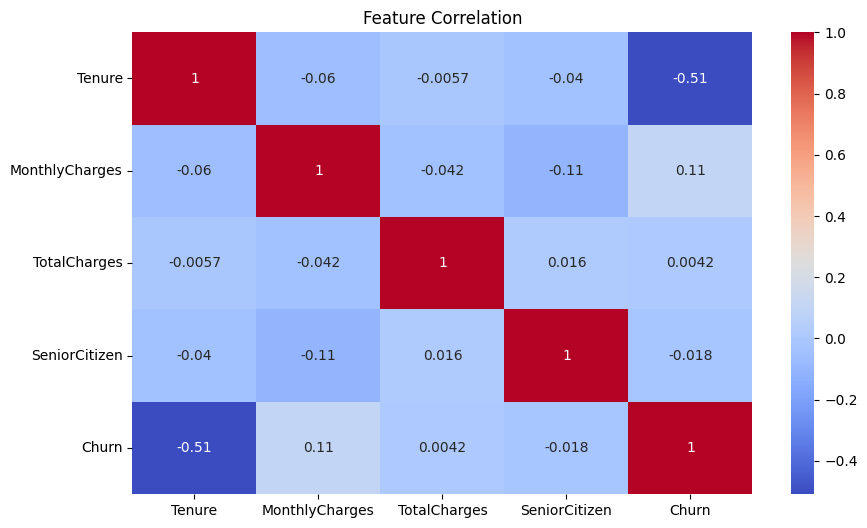

In [6]:
numeric_df = df.select_dtypes(include=['number'])

correlation = numeric_df.corr()

plt.figure(figsize=(10,6))
sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.title('Feature Correlation')
plt.show()

In [7]:
print(correlation['Churn'].sort_values(ascending=False))

Churn             1.000000
MonthlyCharges    0.107381
TotalCharges      0.004250
SeniorCitizen    -0.018114
Tenure           -0.509208
Name: Churn, dtype: float64


In [8]:
from sklearn.ensemble import RandomForestClassifier

X = numeric_df.drop('Churn', axis=1)
y = numeric_df['Churn']

model = RandomForestClassifier(random_state=42)
model.fit(X, y)

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

Tenure            0.663909
TotalCharges      0.158922
MonthlyCharges    0.155441
SeniorCitizen     0.021728
dtype: float64


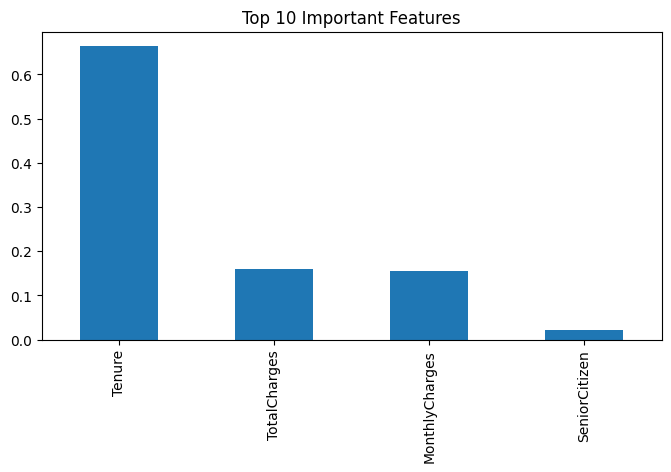

In [9]:
importance.head(10).plot(kind='bar', figsize=(8,4))

plt.title('Top 10 Important Features')
plt.show()

In [10]:
selected_features = importance.head(10).index.tolist()

X_selected = X[selected_features]

print(selected_features)

['Tenure', 'TotalCharges', 'MonthlyCharges', 'SeniorCitizen']


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

In [12]:
X = numeric_df.drop('Churn', axis=1)
y = numeric_df['Churn']

In [13]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])

In [15]:
pipeline.fit(X, y)

print("Pipeline trained successfully!")

Pipeline trained successfully!


In [16]:
predictions = pipeline.predict(X)

print("Predictions:", predictions[:10])

Predictions: [0 0 0 0 0 0 0 0 0 0]


In [17]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y, predictions)

print("Model Accuracy:", accuracy)

Model Accuracy: 1.0


In [18]:
import joblib

joblib.dump(pipeline, 'churn_pipeline.pkl')

print("Pipeline saved successfully!")

Pipeline saved successfully!


In [19]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
scikit-learn
scipy
joblib

Writing requirements.txt


In [23]:
from google.colab import files

In [24]:
files.download('customer_churn.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
files.download('requirements.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Customer Churn Prediction – Preprocessing Report

## 1. Project Overview
This project focuses on preprocessing customer data for machine learning and customer churn prediction.

## 2. Data Exploration
- Loaded customer churn dataset.
- Checked data types and dataset shape.
- Checked missing values and duplicates.
- Analyzed churn distribution.

## 3. Data Encoding
- Label Encoding
- One-Hot Encoding
- Ordinal Encoding

## 4. Feature Scaling
- Min-Max Scaling
- Standard Scaling

## 5. Outlier Handling
- IQR Method
- Z-Score Method

## 6. Feature Selection
Used correlation analysis and Random Forest feature importance.

## 7. Final Result
Created a preprocessing pipeline using Scikit-learn.

## 8. Tools
Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.